### Subagents
A deep agent can create subagents to delegate work. You can specify custom subagents in the subagents parameter. Subagents are useful for context quarantine (keeping the main agent’s context clean) and for providing specialized instructions.
This page covers synchronous subagents, where the supervisor blocks until the subagent finishes. For long-running tasks, parallel workstreams, or cases where you need mid-flight steering and cancellation, see Async subagents.

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [20]:
from langchain_ollama import ChatOllama
model = ChatOllama(
    model="qwen3:8b",
    temperature=0,
)

dp_model = ChatOllama(
    model='deepseek-r1:8b',
    temperature=0.2,
)

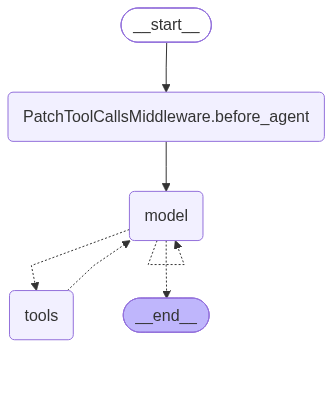

In [18]:
import os
from typing import Literal

from deepagents import create_deep_agent
from tavily import TavilyClient

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,

):
 """Run a web search"""
 return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )


research_subagent={
    "name": "research-agent",
    "description": "Used to research more in depth questions",
    "system_prompt": "You are a great researcher",
    "tools": [internet_search],
    "model": "groq:qwen/qwen3-32b",  # Optional override, defaults to main agent model

}
subagents=[research_subagent]

agent=create_deep_agent(
    model=model, #"groq:qwen/qwen3-32b",
    subagents=subagents
)
agent


In [19]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "Reserach about LLM Gateways and provide me a detailed summary.",       
          }],
          
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Reserach about LLM Gateways and provide me a detailed summary.
================================== Ai Message ==================================
Tool Calls:
  task (116c05d1-ebba-4006-9e27-6c37761f97b3)
 Call ID: 116c05d1-ebba-4006-9e27-6c37761f97b3
  Args:
    description: Research LLM Gateways and provide a detailed summary covering their definition, architecture, key features, use cases, and significance in AI infrastructure. Include examples of popular gateways and their roles in managing large language models.
    subagent_type: general-purpose
================================= Tool Message =================================
Name: task

LLM Gateways are systems that act as intermediaries between large language models (LLMs) and end-users or applications, enabling efficient, secure, and scalable deployment of AI models. They provide a unified interface for interacting with multiple models, managing traf

In [21]:
result

{'messages': [HumanMessage(content='Reserach about LLM Gateways and provide me a detailed summary.', additional_kwargs={}, response_metadata={}, id='0690edea-1591-442f-8071-6dda5c78e74d'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-02T13:21:54.60702Z', 'done': True, 'done_reason': 'stop', 'total_duration': 45583605416, 'load_duration': 4250954500, 'prompt_eval_count': 2288, 'prompt_eval_duration': 10945730000, 'eval_count': 621, 'eval_duration': 30315376000, 'logprobs': None, 'model_name': 'qwen3:8b', 'model_provider': 'ollama'}, id='lc_run--01a0fcc6-9995-71b2-8bc4-1d267e464501-0', tool_calls=[{'name': 'task', 'args': {'description': 'Research LLM Gateways and provide a detailed summary covering their definition, architecture, key features, use cases, and significance in AI infrastructure. Include examples of popular gateways and their roles in managing large language models.', 'subagent_type': 'general-purpose'}, 'id': 

### structured Output With Sub Agents

In [22]:
from pydantic import BaseModel, Field
from deepagents import create_deep_agent

class ResearchFindings(BaseModel):
    """Structured findings from a research task."""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(description="Confidence score from 0 to 1")
    sources: list[str] = Field(description="List of source URLs")

research_subagent = {
    "name": "researcher",
    "description": "Researches topics and returns structured findings",
    "system_prompt": "Research the given topic thoroughly. Return your findings.",
    "tools": [internet_search],
    "response_format": ResearchFindings,
}

agent = create_deep_agent(
    model=model,
    subagents=[research_subagent],
)

result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "Research recent advances in quantum computing"}]}
)

In [24]:
# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.

print(result)


for m in result["messages"]:
    m.pretty_print()

{'messages': [HumanMessage(content='Research recent advances in quantum computing', additional_kwargs={}, response_metadata={}, id='aee1eabe-2ca4-4ed5-955b-d8a9ef8a72d3'), AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-02T13:25:32.192651Z', 'done': True, 'done_reason': 'stop', 'total_duration': 23555989708, 'load_duration': 18053917, 'prompt_eval_count': 2278, 'prompt_eval_duration': 2003962000, 'eval_count': 420, 'eval_duration': 21161639000, 'logprobs': None, 'model_name': 'qwen3:8b', 'model_provider': 'ollama'}, id='lc_run--01a0fcca-4173-7632-91ab-0ac6e9a1ff43-0', tool_calls=[{'name': 'task', 'args': {'description': 'Research recent advances in quantum computing, focusing on breakthroughs in quantum algorithms, hardware developments (e.g., qubit stability, error correction), and experimental milestones. Prioritize peer-reviewed papers from the last 2 years and notable industry announcements.', 'subagent_type': 'researcher'}